# 09 — Two detectors: coincidence and time slides

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**Why this notebook.** Every false-alarm probability of notebooks 03–08 is *per one-second window of H1 alone*: the glitch floor of a single interferometer (a few 10⁻³ per window) prevents us from going below FAP ≈ 10⁻³ and is what makes low false-alarm probabilities so expensive. A real search requires a candidate to be present, with a compatible arrival time, in **both** LIGO detectors, and measures the background with **time slides** (shifting one detector's data by more than the light-travel time, so that no real signal is coincident and the pairs sample the accidental coincidences of independent noise).

**What it does**
1. Uses six 4096 s chunks with **both H1 and L1 in science mode** (`download_coinc_data.py`; two of them are chunks 0 and 6 of the single-detector study), whitened exactly as before, and the windows of the two detectors that are simultaneous.
2. Builds the background of coincident statistics with **time slides** of whole one-second windows ($\approx6.5\times10^7$ pairs), reaching FAP down to $10^{-6}$; checks it against the **zero-lag** (simultaneous) windows of two test chunks.
3. Compares single-detector and coincident detection at the same FAP for four statistics: the IMR bank, the sine-Gaussian bank (both with a ±15 ms arrival-time consistency requirement), the CNN trained with IMR signals (sum of the two logits) and excess power (sum of the z-scores), on binary-black-hole (IMR) and sine-Gaussian injections placed in both detectors with a random relative delay (±10 ms) and a random split of the network SNR between the two.

**What it does not do**: no sky localisation, no coherent (phase-consistent) network statistic, no antenna-pattern consistency between the two detectors (the same waveform shape is injected in both, with different amplitudes); the CNN was trained on H1 data and is applied to L1 as it is; the chunks are only 4096 s each, so "time slides" are slides of whole windows (≥ 2 s). The false-alarm probabilities are **per one-second window**, i.e. they are still not astrophysical rates (FAP 10⁻⁶ per second is about one false alarm every 11.6 days of coincident livetime), though they are a realistic step towards it.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import imr_tools as it
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
rng = np.random.default_rng(909)

CHK = g.load_json("coinc_chunks.json"); K = len(CHK)
W = {det: [g.load_coinc_chunk(k, det) for k in range(K)] for det in ("H1", "L1")}
N = [len(W["H1"][k]["v"]) for k in range(K)]; assert N == [len(W["L1"][k]["v"]) for k in range(K)]
BKG_IDX, TEST_IDX = [0, 1, 3, 4], [2, 5]
print("chunks:", [c["gps_start"] for c in CHK], " windows per chunk:", N)
print("background (time slides) chunks:", BKG_IDX, "  test chunks (zero-lag check and injections):", TEST_IDX)
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 20, 24, 30]; NINJ = 400
GATE = 0.015           # arrival-time consistency [s]: 10 ms light travel time + reconstruction error
summary = {}

chunks: [1126076416, 1126080512, 1129517056, 1133064192, 1135579136, 1137242112]  windows per chunk: [4056, 4056, 4056, 4056, 4056, 4056]
background (time slides) chunks: [0, 1, 3, 4]   test chunks (zero-lag check and injections): [2, 5]


## 1. Single-detector statistics of every window

For every window of both detectors: the sine-Gaussian bank and the IMR bank (maximum $\rho^2$ and the lag of the maximum), the CNN logit (ensemble of the two seeds of `cnn_fresh_imr`, notebook 08) and the excess-power statistic (fitted on the background windows of each detector).

In [2]:
BANK = {("sg", d, k): g.SGBank(W[d][k]["S1"]) for d in ("H1", "L1") for k in range(K)}
BANK.update({("imr", d, k): it.IMRBank(W[d][k]["S1"]) for d in ("H1", "L1") for k in range(K)})
NETS = [sm.train_variant("cnn_fresh_imr", None, None, seed=s, verbose=False)[0] for s in (0, 1)]      # cached by notebook 08 / seq_models.py
logit = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in NETS], 0)
EP = {d: g.ExcessPower().fit(np.concatenate([W[d][k]["v"] for k in BKG_IDX])) for d in ("H1", "L1")}

def single_stats(v, d, k_arr):
    # k_arr: chunk index of each window (windows of one chunk or a mixture)
    out = {}
    for kind in ("sg", "imr"):
        o = g.scan_mixed(v, k_arr, {k: BANK[(kind, d, k)] for k in np.unique(k_arr)})
        out[kind] = o["rho2"]; out[kind + "_tau"] = o["tau"]
    out["cnn"] = logit(v); out["ep"] = EP[d].stat(v); return out
t0_ = time.time()
ST = {d: [single_stats(W[d][k]["v"], d, np.full(N[k], k)) for k in range(K)] for d in ("H1", "L1")}
print("single-detector statistics of all windows: %.0f s" % (time.time() - t0_))

single-detector statistics of all windows: 106 s


### Single-detector background of the two interferometers

The glitch floor, one detector at a time (sine-Gaussian bank statistic on the background chunks):

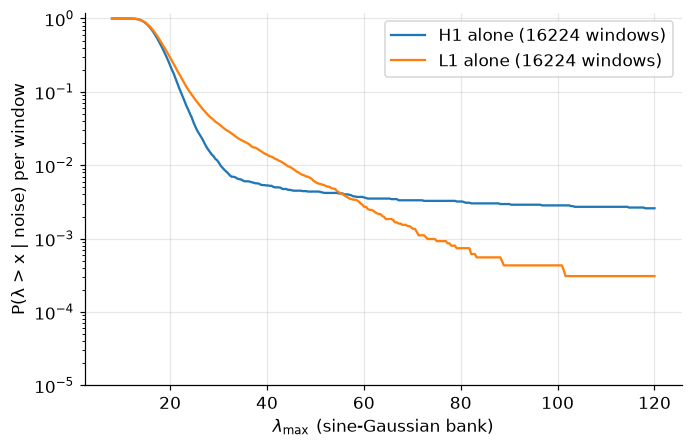

In [3]:
def surv(x, grid):
    xs = np.sort(x); return 1 - np.searchsorted(xs, grid, side="right") / len(xs)
grid = np.linspace(8, 120, 300)
fig, ax = plt.subplots(figsize=(7, 4.4))
for d, c in (("H1", g.COLORS["H1"]), ("L1", g.COLORS["L1"])):
    x = np.concatenate([ST[d][k]["sg"] for k in BKG_IDX]); ax.semilogy(grid, np.maximum(surv(x, grid), 1e-5), color=c, label=f"{d} alone ({len(x)} windows)")
ax.set_xlabel(r"$\lambda_{\max}$ (sine-Gaussian bank)"); ax.set_ylabel("P(λ > x | noise) per window"); ax.set_ylim(1e-5, 1.2); ax.legend()
g.savefig(fig, "fig09_single_detector_background"); plt.show()

## 2. Coincident statistics and the time-slide background

The coincident statistic of a pair of simultaneous windows is the **Fisher combination** $-\ln p_H-\ln p_L$, where $p_d$ is the empirical p-value of the single-detector statistic of detector $d$ (rank in that detector's own background of the four background chunks; a statistic beyond the whole background counts $\ln(N+1)\approx9.7$). For the two banks the pair is **rejected** (statistic 0) unless $|\tau_H-\tau_L|\le15$ ms. A plain sum of the statistics was tried first and discarded: it is dominated by a loud glitch in one detector (the tail of the sum is the single-detector glitch tail of H1, at FAP 10⁻⁵ a threshold of $\rho^2\approx10^3$, not the tail of accidental coincidences), which the p-value combination removes. The background is made by pairing every H1 window of a chunk with every L1 window of the **same chunk** at a different time (offsets of 2 to $N-2$ windows): the noise of the two detectors is independent, so the pairs sample the accidental coincidences. Only the exceedances above a low floor are stored; the tail quantiles give the thresholds for FAP ≤ 10⁻².

In [4]:
KINDS = {"sg": "sine-Gaussian bank", "imr": "IMR bank", "cnn": "CNN (fresh + IMR)", "ep": "excess power"}
SINGLE = {d: {kind: np.concatenate([ST[d][k][kind] for k in BKG_IDX]) for kind in KINDS} for d in ("H1", "L1")}      # single-detector background (16 224 windows)
# A plain sum of the two statistics is dominated by a loud glitch in ONE detector (the tail of the sum is then the glitch tail of H1, not
# that of accidental coincidences). Each statistic is therefore first converted into the empirical p-value of that detector (rank in its own
# single-detector background) and the network statistic is the Fisher combination -ln p_H - ln p_L: a glitch beyond the whole background
# counts at most ln(N+1) = 9.7, so a candidate needs evidence in BOTH detectors.
def pv_scores(stats, d):
    out = dict(stats)
    for kind in KINDS:
        B = np.sort(SINGLE[d][kind]); n = len(B)
        out["s_" + kind] = -np.log((n - np.searchsorted(B, stats[kind], side="left") + 1.0) / (n + 1.0))
    return out
ST = {d: [pv_scores(st, d) for st in ST[d]] for d in ("H1", "L1")}
def net_stat(kind, H, L, idxL=None):
    # H, L: dicts of single-detector statistics (arrays); L is indexed with idxL (time slide) if given
    sl = (lambda a: a) if idxL is None else (lambda a: a[idxL])
    s = H["s_" + kind] + sl(L["s_" + kind])
    if kind in ("sg", "imr"):
        ok = np.abs(H[kind + "_tau"] - sl(L[kind + "_tau"])) <= GATE
        return np.where(ok, s, 0.0)
    return s

def slide_background(kind, chunks, floor_q=0.985, nsample=60):
    # floor from a sample of offsets, then every offset: store the exceedances; returns (sorted exceedances desc, number of pairs, floor)
    samp = np.concatenate([net_stat(kind, ST["H1"][k], ST["L1"][k], (np.arange(N[k]) + s) % N[k]) for k in chunks for s in rng.integers(2, N[k] - 2, nsample)])
    floor = np.quantile(samp, floor_q); ex = []; npairs = 0
    for k in chunks:
        for s in range(2, N[k] - 1):
            v = net_stat(kind, ST["H1"][k], ST["L1"][k], (np.arange(N[k]) + s) % N[k]); ex.append(v[v > floor]); npairs += N[k]
    return np.sort(np.concatenate(ex))[::-1], npairs, floor
t0_ = time.time(); BG = {kind: slide_background(kind, BKG_IDX) for kind in KINDS}
print("time-slide background: %.0f s;  pairs %.2e per statistic" % (time.time() - t0_, BG["sg"][1]))
FAPS = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
def thr_coinc(kind, far):
    ex, npairs, floor = BG[kind]; k = int(far * npairs); assert k < len(ex), (kind, far); return ex[k]
THR = {kind: {far: thr_coinc(kind, far) for far in FAPS} for kind in KINDS}
pd.DataFrame(THR).T.round(2)

time-slide background: 2 s;  pairs 6.58e+07 per statistic


,0.010000,0.001000,0.000100,0.000010,0.000001
sg,2.77,5.60,8.08,10.15,12.03
imr,2.78,5.62,8.08,10.10,11.99
cnn,6.62,9.00,10.87,12.57,14.04
ep,6.59,8.97,10.93,12.73,14.31


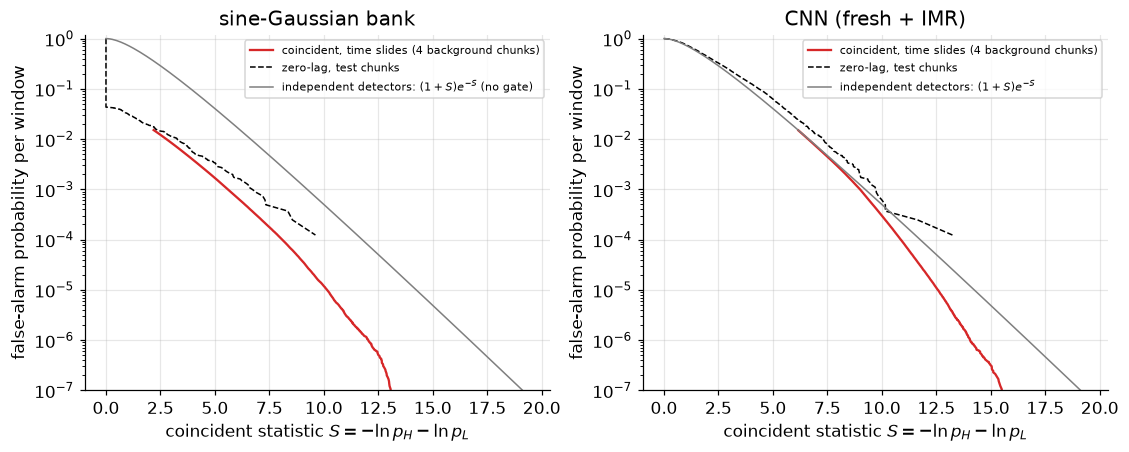

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, kind in zip(ax, ("sg", "cnn")):
    ex, npairs, floor = BG[kind]
    xs = ex[::-1]; sf = (len(xs) - np.arange(len(xs))) / npairs
    a.semilogy(xs, sf, color=g.COLORS["bayes"], label="coincident, time slides (4 background chunks)")
    z = np.sort(np.concatenate([net_stat(kind, ST["H1"][k], ST["L1"][k]) for k in TEST_IDX])); a.semilogy(z, 1 - np.arange(len(z)) / len(z), "k--", lw=1, label="zero-lag, test chunks")
    S = np.linspace(0, 19.4, 200); a.semilogy(S, (1 + S) * np.exp(-S), color=g.COLORS["grey"], lw=1, label=r"independent detectors: $(1+S)e^{-S}$" + (" (no gate)" if kind in ("sg", "imr") else ""))
    a.set_ylim(1e-7, 1.2); a.set_xlabel(r"coincident statistic $S=-\ln p_H-\ln p_L$"); a.set_ylabel("false-alarm probability per window"); a.set_title(KINDS[kind]); a.legend(fontsize=7.5)
g.savefig(fig, "fig09_coincident_background"); plt.show()

The coincident background from time slides (red) follows the curve expected for two independent detectors, $(1+S)e^{-S}$ (grey), and is **below** it for the banks because of the arrival-time requirement (a random pair is coincident within 15 ms about 4 % of the time). An accidental coincidence needs *two* independent glitches or noise fluctuations: this is what moves the FAP floor from $10^{-3}$ (one detector) to $10^{-6}$ and below. The dashed black curve is the **zero-lag** distribution of the two test chunks (simultaneous windows, no injections); if the noise of the two detectors were not independent (common environmental noise), it would lie above the slides.

### Calibration check: zero-lag against time slides

In [6]:
rows = []
for kind in KINDS:
    z = np.concatenate([net_stat(kind, ST["H1"][k], ST["L1"][k]) for k in TEST_IDX])
    for far in (1e-2, 1e-3):
        thr = thr_coinc(kind, far); obs = int((z > thr).sum()); exp = far * len(z)
        rows.append(dict(statistic=KINDS[kind], FAP=far, threshold=thr, observed_zero_lag=obs, expected=exp, ratio=obs / exp))
cal = pd.DataFrame(rows); cal["thresholds_from"] = "slides of the 4 background chunks (other epochs)"
# the real test of the independence of the two noises: zero-lag against time slides of the SAME chunks
rows = []
BG_T = {kind: slide_background(kind, TEST_IDX) for kind in KINDS}
for kind in KINDS:
    z = np.concatenate([net_stat(kind, ST["H1"][k], ST["L1"][k]) for k in TEST_IDX]); ex, npairs, floor = BG_T[kind]
    for far in (1e-2, 1e-3):
        thr = ex[int(far * npairs)]; obs = int((z > thr).sum()); exp = far * len(z)
        rows.append(dict(statistic=KINDS[kind], FAP=far, threshold=thr, observed_zero_lag=obs, expected=exp, ratio=obs / exp))
cal_same = pd.DataFrame(rows); cal_same["thresholds_from"] = "slides of the same (test) chunks"
print("zero-lag against time slides of the SAME chunks (independent noises -> ratio ~ 1):"); display(cal_same.round(3))
print("zero-lag against slides of the background chunks (adds the epoch dependence):"); display(cal.round(3))

zero-lag against time slides of the SAME chunks (independent noises -> ratio ~ 1):


,statistic,FAP,threshold,observed_zero_lag,expected,ratio,thresholds_from
0,sine-Gaussian bank,0.010,3.197,85,81.120,1.048,slides of the same (test) chunks
1,sine-Gaussian bank,0.001,7.285,5,8.112,0.616,slides of the same (test) chunks
2,IMR bank,0.010,4.279,71,81.120,0.875,slides of the same (test) chunks
3,IMR bank,0.001,7.744,8,8.112,0.986,slides of the same (test) chunks
4,CNN (fresh + IMR),0.010,7.377,71,81.120,0.875,slides of the same (test) chunks
5,CNN (fresh + IMR),0.001,9.611,9,8.112,1.109,slides of the same (test) chunks
6,excess power,0.010,8.317,90,81.120,1.109,slides of the same (test) chunks
7,excess power,0.001,10.287,8,8.112,0.986,slides of the same (test) chunks


zero-lag against slides of the background chunks (adds the epoch dependence):


,statistic,FAP,threshold,observed_zero_lag,expected,ratio,thresholds_from
0,sine-Gaussian bank,0.010,2.769,103,81.120,1.270,slides of the 4 background chunks (other epochs)
1,sine-Gaussian bank,0.001,5.598,17,8.112,2.096,slides of the 4 background chunks (other epochs)
2,IMR bank,0.010,2.780,133,81.120,1.640,slides of the 4 background chunks (other epochs)
3,IMR bank,0.001,5.623,42,8.112,5.178,slides of the 4 background chunks (other epochs)
4,CNN (fresh + IMR),0.010,6.615,138,81.120,1.701,slides of the 4 background chunks (other epochs)
5,CNN (fresh + IMR),0.001,8.997,16,8.112,1.972,slides of the 4 background chunks (other epochs)
6,excess power,0.010,6.591,443,81.120,5.461,slides of the 4 background chunks (other epochs)
7,excess power,0.001,8.965,40,8.112,4.931,slides of the 4 background chunks (other epochs)


## 3. Injections: single detector against coincidence

Injections in the test chunks, at the same window of H1 and L1: a library IMR signal (or a sine-Gaussian) with network optimal SNR $\rho_{\rm net}=\sqrt{\rho_H^2+\rho_L^2}$, split as $\rho_H=\rho_{\rm net}\cos\alpha$, $\rho_L=\rho_{\rm net}\sin\alpha$ with $\alpha\sim U(0.45,1.12)$ rad (H1/L1 amplitude ratio between 0.5 and 2.0, as for GW150914 ≈ 1.5) and a random relative delay of ±10 ms. A single detector sees only its own share of the network SNR — this is part of what a network gains.

In [7]:
def inject_pair(kind, snr, r):
    ks = r.choice(TEST_IDX, NINJ); ii = np.array([r.integers(0, N[k]) for k in ks])
    alpha = r.uniform(0.45, 1.12, NINJ); dt = r.uniform(-0.01, 0.01, NINJ)
    gkind = "imr_test" if kind == "imr" else kind          # evaluation uses the held-out IMR library
    p = g.draw_params(gkind, r, NINJ); pH = dict(p, t0=p["t0"] + dt / 2); pL = dict(p, t0=p["t0"] - dt / 2)
    out = {}
    for d, pp, rho in (("H1", pH, snr * np.cos(alpha)), ("L1", pL, snr * np.sin(alpha))):
        v = np.stack([W[d][k]["v"][i] for k, i in zip(ks, ii)]); S1 = np.stack([W[d][k]["S1"] for k in ks])
        ser, _, _ = g.inject(v, gkind, rho, r, S1, params=pp); out[d] = pv_scores(single_stats(ser, d, ks), d)
    return out
r = np.random.default_rng(31); INJ = {}
t0_ = time.time()
for kind in ("imr", "sg"):
    for snr in SNRS: INJ[(kind, snr)] = inject_pair(kind, float(snr), r)
print("injections: %.0f s" % (time.time() - t0_))

injections: 63 s


In [8]:
def levels(e):
    x = np.array(SNRS, float); f = lambda lv: float(np.interp(lv, np.maximum.accumulate(e), x)) if e.max() >= lv else np.nan
    return f(.5), f(.9)
# single-detector thresholds from the own background of each detector (16 224 windows: FAP >= 1e-3)
rows = []
for injk in ("imr", "sg"):
    for kind in KINDS:
        for far in FAPS:
            e = np.array([g.efficiency(net_stat(kind, INJ[(injk, s)]["H1"], INJ[(injk, s)]["L1"]), THR[kind][far])[0] for s in SNRS]); r50, r90 = levels(e)
            rows.append(dict(injection=injk, statistic=KINDS[kind], mode="coincident (H1+L1)", FAP=far, rho50=r50, rho90=r90, curve=e.tolist()))
        for d in ("H1", "L1"):
            for far in (1e-2, 1e-3):
                t = g.threshold_at_far(SINGLE[d][kind], far)
                e = np.array([g.efficiency(INJ[(injk, s)][d][kind], t)[0] for s in SNRS]); r50, r90 = levels(e)
                rows.append(dict(injection=injk, statistic=KINDS[kind], mode=f"{d} alone", FAP=far, rho50=r50, rho90=r90, curve=e.tolist()))
res = pd.DataFrame(rows)
for injk in ("imr", "sg"):
    print(f"rho50 in terms of the NETWORK optimal SNR, {injk} injections")
    t = res[res.injection == injk].pivot_table(index=["statistic", "mode"], columns="FAP", values="rho50"); display(t.round(2))

rho50 in terms of the NETWORK optimal SNR, imr injections


FAP                                    0.000001  0.000010  0.000100  0.001000  \
statistic          mode                                                         
CNN (fresh + IMR)  H1 alone                 NaN       NaN       NaN      9.75   
                   L1 alone                 NaN       NaN       NaN      9.77   
                   coincident (H1+L1)     10.95      9.74      8.22      6.78   
IMR bank           H1 alone                 NaN       NaN       NaN       NaN   
                   L1 alone                 NaN       NaN       NaN     10.85   
                   coincident (H1+L1)     11.04      9.72      8.48      7.63   
excess power       H1 alone                 NaN       NaN       NaN       NaN   
                   L1 alone                 NaN       NaN       NaN     15.85   
                   coincident (H1+L1)       NaN     18.86     15.32     12.88   
sine-Gaussian bank H1 alone                 NaN       NaN       NaN       NaN   
                   L1 alone                 NaN       NaN       NaN     18.33   
                   coincident (H1+L1)     20.40     16.62     14.28     12.86   

FAP                                    0.010000  
statistic          mode                          
CNN (fresh + IMR)  H1 alone                6.89  
                   L1 alone                7.70  
                   coincident (H1+L1)      4.05  
IMR bank           H1 alone                7.53  
                   L1 alone                8.54  
                   coincident (H1+L1)      7.38  
excess power       H1 alone               11.74  
                   L1 alone               12.82  
                   coincident (H1+L1)     10.45  
sine-Gaussian bank H1 alone               11.08  
                   L1 alone               13.84  
                   coincident (H1+L1)     12.38

rho50 in terms of the NETWORK optimal SNR, sg injections


FAP                                    0.000001  0.000010  0.000100  0.001000  \
statistic          mode                                                         
CNN (fresh + IMR)  H1 alone                 NaN       NaN       NaN      9.65   
                   L1 alone                 NaN       NaN       NaN      9.88   
                   coincident (H1+L1)     11.00      9.56      8.05      6.80   
IMR bank           H1 alone                 NaN       NaN       NaN       NaN   
                   L1 alone                 NaN       NaN       NaN     18.47   
                   coincident (H1+L1)     21.51     18.38     15.73     13.84   
excess power       H1 alone                 NaN       NaN       NaN       NaN   
                   L1 alone                 NaN       NaN       NaN     14.62   
                   coincident (H1+L1)       NaN     15.91     13.61     10.88   
sine-Gaussian bank H1 alone                 NaN       NaN       NaN       NaN   
                   L1 alone                 NaN       NaN       NaN     12.36   
                   coincident (H1+L1)     12.19     10.34      8.47      7.57   

FAP                                    0.010000  
statistic          mode                          
CNN (fresh + IMR)  H1 alone                7.11  
                   L1 alone                7.45  
                   coincident (H1+L1)      4.14  
IMR bank           H1 alone               11.77  
                   L1 alone               14.35  
                   coincident (H1+L1)     13.16  
excess power       H1 alone                9.40  
                   L1 alone               11.00  
                   coincident (H1+L1)      8.52  
sine-Gaussian bank H1 alone                7.29  
                   L1 alone                9.18  
                   coincident (H1+L1)      7.08

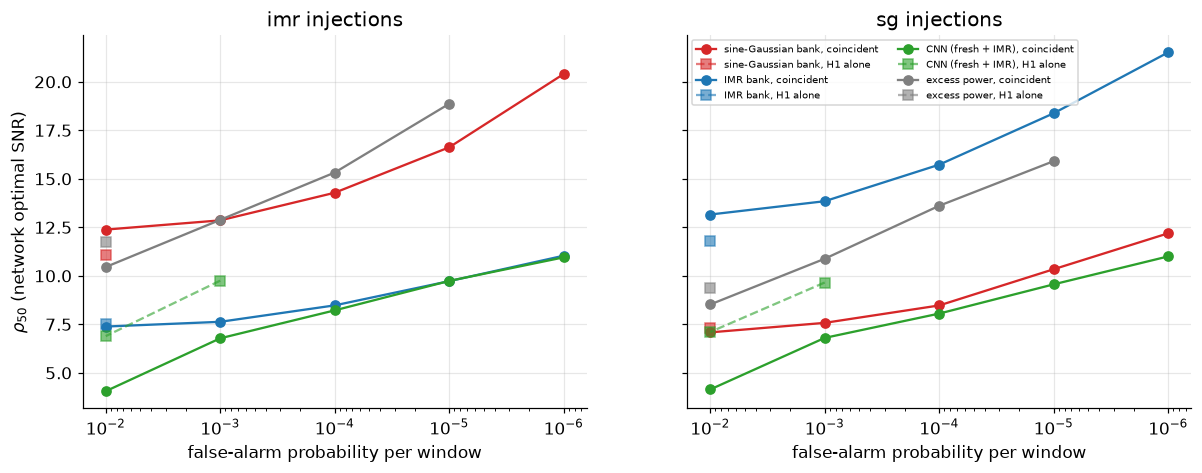

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
colr = {"sine-Gaussian bank": "#d62728", "IMR bank": "#1f77b4", "CNN (fresh + IMR)": "#2ca02c", "excess power": "#7f7f7f"}
for a, injk in zip(ax, ("imr", "sg")):
    for name in KINDS.values():
        d = res[(res.injection == injk) & (res.statistic == name)]
        c = d[d["mode"] == "coincident (H1+L1)"].sort_values("FAP"); a.plot(c.FAP, c.rho50, "o-", color=colr[name], label=f"{name}, coincident")
        s = d[d["mode"] == "H1 alone"].sort_values("FAP"); a.plot(s.FAP, s.rho50, "s--", color=colr[name], alpha=.6, label=f"{name}, H1 alone")
    a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel("false-alarm probability per window"); a.set_title(f"{injk} injections"); a.grid(True, alpha=.3)
ax[0].set_ylabel(r"$\rho_{50}$ (network optimal SNR)"); ax[1].legend(fontsize=6.5, ncol=2)
g.savefig(fig, "fig09_rho50_vs_fap"); plt.show()

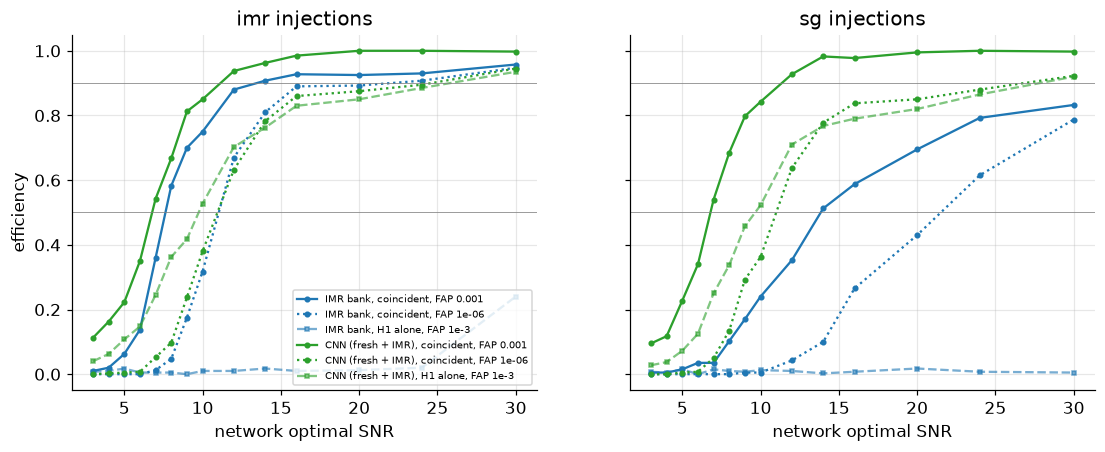

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for a, injk in zip(ax, ("imr", "sg")):
    for name, kind in (("IMR bank", "imr"), ("CNN (fresh + IMR)", "cnn")):
        for far, ls in ((1e-3, "-"), (1e-6, ":")):
            e = res[(res.injection == injk) & (res.statistic == name) & (res["mode"] == "coincident (H1+L1)") & (res.FAP == far)].curve.iloc[0]; a.plot(SNRS, e, ls=ls, marker="o", ms=3, color=colr[name], label=f"{name}, coincident, FAP {far:g}")
        e = res[(res.injection == injk) & (res.statistic == name) & (res["mode"] == "H1 alone") & (res.FAP == 1e-3)].curve.iloc[0]; a.plot(SNRS, e, "--", marker="s", ms=3, color=colr[name], alpha=.6, label=f"{name}, H1 alone, FAP 1e-3")
    a.set_xlabel("network optimal SNR"); a.set_title(f"{injk} injections"); a.axhline(.5, color="grey", lw=.5); a.axhline(.9, color="grey", lw=.5)
ax[0].set_ylabel("efficiency"); ax[0].legend(fontsize=6.5, loc="lower right")
g.savefig(fig, "fig09_efficiency"); plt.show()

In [11]:
summary.update(chunks=[c["gps_start"] for c in CHK], windows=N, bkg_idx=BKG_IDX, test_idx=TEST_IDX, gate_s=GATE, n_pairs=int(BG["sg"][1]), thresholds={k: {str(f): float(v) for f, v in d.items()} for k, d in THR.items()},
               zero_lag=cal.to_dict("records"), zero_lag_same_chunks=cal_same.to_dict("records"), detection=res.drop(columns="curve").to_dict("records"), curves={f"{r.injection}|{r.statistic}|{r.mode}|{r.FAP}": r.curve for r in res.itertuples()}, snrs=SNRS)
g.save_json(summary, "09_summary.json"); print("saved")

saved



## Conclusions

(ρ₅₀ is in terms of the **network** optimal SNR $\sqrt{\rho_H^2+\rho_L^2}$; a single detector sees only its own share $\rho_H$ or $\rho_L$, on average about 0.7 of it.)

1. **The noises of the two interferometers are independent at the level tested.** Zero-lag against time slides **of the same chunks**: 71–90 coincidences above the FAP = 10⁻² threshold against 81 expected, 5–9 above the 10⁻³ threshold against 8.1 expected (ratio 0.6–1.1). Against the slides of *other* epochs the ratio is 1.3–1.7 for the CNN and the banks and 5 for excess power: the **epoch dependence** of the background, already seen in a single detector, survives coincidence.
2. **Coincidence moves the false-alarm floor from 10⁻³ to 10⁻⁶ and below.** The time-slide background (6.6·10⁷ pairs) follows the curve $(1+S)e^{-S}$ expected for independent detectors (CNN), and is below it for the banks because of the 15 ms arrival-time requirement. The thresholds on the coincident statistic at FAP 10⁻²…10⁻⁶ are 2.8…12.0 for the banks and 6.6…14.0 for the CNN and excess power.
3. **Detection at low FAP, in network SNR (binary-black-hole injections):** CNN trained with IMR signals 4.1 / 6.8 / 8.2 / 9.7 / 11.0 at FAP 10⁻² / 10⁻³ / 10⁻⁴ / 10⁻⁵ / 10⁻⁶; IMR bank 7.4 / 7.6 / 8.5 / 9.7 / 11.0; sine-Gaussian bank 12.4 / 12.9 / 14.3 / 16.6 / 20.4; excess power 10.5 / 12.9 / 15.3 / 18.9 / –. A single detector cannot go below FAP 10⁻³: H1 alone, CNN 6.9 (10⁻²) and 9.8 (10⁻³); the IMR bank of H1 alone does not reach 50 % efficiency at FAP 10⁻³ up to a network SNR of 30, because of the glitch tail of the H1 data. Lowering the FAP by four orders of magnitude costs only ≈ 3.7 (IMR bank) to 6.9 (CNN) in network SNR with two detectors. At FAP 10⁻⁶ per window the network SNR needed is **≈ 11** for both the CNN and the IMR bank, the same order as the thresholds of real searches (though those work at much lower rates).
4. **Which statistic?** The ranking of notebook 08 survives coincidence: the burst statistics (sine-Gaussian bank, excess power) are 2–3 times worse on binary-black-hole signals, and on sine-Gaussian injections the sine-Gaussian bank and the CNN are the best (7.1 / 7.6 / 8.5 / 10.3 / 12.2 and 4.1 / 6.8 / 8.1 / 9.6 / 11.0). The IMR bank is useless on sine-Gaussians (13.2 at FAP 10⁻²), as expected for a bank of the wrong family.
5. **The statistic used for the combination matters.** A plain sum of the single-detector statistics (tried first) is dominated by loud glitches of one detector: with the plain sum the 10⁻⁵ threshold of the sine-Gaussian bank was a statistic of ≈ 3·10⁵, and still ≈ 10³ after capping the contribution of each detector at its FAP = 10⁻³ value (the H1 data contain loud glitches at the 10⁻³ level). Converting each statistic into the empirical p-value of its detector and summing $-\ln p$ removes the problem; real pipelines use signal-consistency tests ($\chi^2$ vetoes) for the same purpose, not implemented here.

**Caveats.** No coherent (phase-consistent) network statistic and no antenna-pattern consistency; the same waveform shape is injected in both detectors; the CNN was trained on H1 and applied to L1; p-values are resolved down to $6\times10^{-5}$ per detector (16 224 background windows), which limits the Fisher statistic to $S\le19.4$; six chunks of 4096 s; the false-alarm probability is per one-second window pair (10⁻⁶ ≈ one accidental coincidence per 11.6 days of coincident data).


## Output and next step

* `results/09_summary.json`, `figures/fig09_*`; windows of both detectors cached in `cache/win_H1_*.npz`, `cache/win_L1_*.npz`.
* Next: **`10_open_set_goodness_of_fit.ipynb`** — flagging a signal that belongs to none of the hypotheses.